# Sentiment and emotion in MELD conversations

**Question.** How much do nearby turns and vocal cues help us classify an utterance, and what happens when human transcripts are replaced by Whisper transcripts?

This is an offline analysis of segmented MELD dialogues. The context model can read nearby turns on both sides of the target. MELD supplies speaker and turn boundaries.

## 1. Data and labels

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from meld_context import load_rows, make_contexts
from meld_evaluation import evaluate

root = Path.cwd()
out = root / 'outputs'
data = {split: load_rows(root, split) for split in ['train', 'dev', 'test']}
display(pd.DataFrame({
    'utterances': {split: len(rows) for split, rows in data.items()},
    'dialogues': {split: rows.Dialogue_ID.nunique() for split, rows in data.items()},
}))
display(data['train'].Emotion.value_counts().rename('training utterances').to_frame())

C:\Users\prade\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,utterances,dialogues
train,9988,1038
dev,1108,114
test,2610,280


,training utterances
Emotion,
neutral,4709
joy,1743
surprise,1205
anger,1109
sadness,683
disgust,271
fear,268


## 2. Text, context, and audio

- The majority baseline always predicts the most frequent training label.
- TF-IDF measures how informative words and two-word phrases are. Logistic regression turns those features into class probabilities.
- RoBERTa reads the target utterance. The context version adds up to three earlier and two later turns, with local speaker markers. The first token's representation feeds separate 3-class sentiment and 7-class emotion heads. RoBERTa-base has 12 layers and a 768-value representation. RoBERTa-large has 24 layers and 1,024 values.
- Logistic regression uses 1,024 frozen emotion2vec+ audio features per utterance. Weighted averaging combines its probabilities with the text model.

In [2]:
example = make_contexts(data['test'])[5]
print('Example model input on human text')
print(example['gold'])

Example model input on human text
<TARGET_S1> Push 'em out, push 'em out, harder, harder. </s> <OTHER_S1> Come on, Lydia, you can do it. </s> <OTHER_S1> Push! </s> <OTHER_S1> Push 'em out, push 'em out, way out! </s> <OTHER_S1> Let's get that ball and really move, hey, hey, ho, ho.


## 3. Select on development, evaluate on test

The evaluation reloads saved predictions. For each transcript source, it chooses the text model by the mean of sentiment macro F1 and emotion weighted F1 on development data. It chooses the audio weight separately for each task on development data. The official test split then scores those fixed choices.

The training loss gives rarer labels more weight using the square root of inverse class frequency. Macro F1 gives every class equal weight. Weighted F1 weights each class by its frequency. Neutral is much more common than fear or disgust, so we report both.

In [3]:
results = evaluate(root)
settings = json.loads((out / 'final_settings.json').read_text(encoding='utf-8'))
for source, model in settings['selected_models'].items():
    print(source, model, settings['weights'][source])

test = results[results.split == 'test']
columns = ['input', 'model', 'task', 'accuracy', 'macro_f1', 'weighted_f1']
main = test[~test.model.isin(['Same checkpoint', 'Mixed base, target only', 'Mixed base, nearby turns'])]
display(main[columns].reset_index(drop=True))

human context_mixed_roberta-large {'sentiment': {'text': 0.8, 'audio': 0.2}, 'emotion': {'text': 0.8, 'audio': 0.2}}
whisper context_mixed_roberta-large {'sentiment': {'text': 0.7, 'audio': 0.3}, 'emotion': {'text': 0.7, 'audio': 0.3}}


,input,model,task,accuracy,macro_f1,weighted_f1
0,human,Majority,sentiment,48.12,21.66,31.27
1,human,TF-IDF,sentiment,53.75,52.07,54.03
2,human,Utterance RoBERTa,sentiment,70.11,68.00,70.37
3,human,Audio,sentiment,54.06,52.41,54.65
4,human,Selected text,sentiment,72.80,71.17,72.83
5,human,Selected text + audio,sentiment,73.07,71.36,73.09
6,human,Majority,emotion,48.12,9.28,31.27
7,human,TF-IDF,emotion,40.15,30.87,42.22
8,human,Utterance RoBERTa,emotion,61.61,46.88,62.13
9,human,Audio,emotion,37.47,28.30,41.07


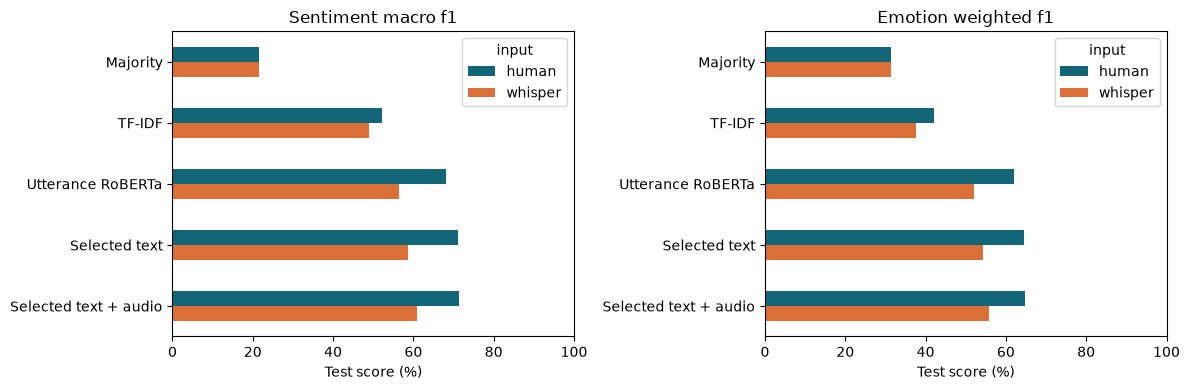

In [4]:
models = ['Majority', 'TF-IDF', 'Utterance RoBERTa', 'Selected text', 'Selected text + audio']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, task, metric in zip(axes, ['sentiment', 'emotion'], ['macro_f1', 'weighted_f1']):
    selected = test[(test.task == task) & test.model.isin(models)]
    chart = selected.pivot(index='model', columns='input', values=metric).reindex(models)
    chart.plot.barh(ax=ax, color=['#126678', '#DA7038'])
    ax.set_title(f'{task.capitalize()} {metric.replace("_", " ")}')
    ax.set_xlim(0, 100)
    ax.set_xlabel('Test score (%)')
    ax.set_ylabel('')
    ax.invert_yaxis()
fig.tight_layout()
plt.show()

## 4. Transcript quality and rare emotions

The next table holds the checkpoint fixed and changes only the transcript supplied at inference. The class report shows where averages hide poor performance.

In [5]:
print('Matched checkpoint:', settings['matched_input_model'])
print(f'Whisper test word error rate: {settings["whisper_test_wer"]:.2f}%')
display(test[test.model == 'Same checkpoint'][columns].reset_index(drop=True))
classes = pd.read_csv(out / 'final_per_class.csv')
display(classes.query("model == 'Selected text + audio' and task == 'emotion'")
        [['input', 'label', 'precision', 'recall', 'f1-score', 'support']].round(3).reset_index(drop=True))

Matched checkpoint: context_mixed_roberta-large
Whisper test word error rate: 34.55%


,input,model,task,accuracy,macro_f1,weighted_f1
0,human,Same checkpoint,sentiment,72.80,71.17,72.83
1,human,Same checkpoint,emotion,64.87,48.45,64.59
2,whisper,Same checkpoint,sentiment,62.07,58.65,61.42
3,whisper,Same checkpoint,emotion,55.59,40.14,54.38


,input,label,precision,recall,f1-score,support
0,human,anger,0.559,0.496,0.525,345.0
1,human,disgust,0.346,0.132,0.191,68.0
2,human,fear,0.188,0.260,0.218,50.0
3,human,joy,0.607,0.692,0.647,402.0
4,human,neutral,0.779,0.764,0.771,1256.0
5,human,sadness,0.448,0.418,0.433,208.0
6,human,surprise,0.556,0.641,0.595,281.0
7,whisper,anger,0.526,0.354,0.423,345.0
8,whisper,disgust,0.257,0.132,0.175,68.0
9,whisper,fear,0.138,0.160,0.148,50.0


### A controlled context comparison

Both window settings use the same RoBERTa-base, mixed training transcripts, and training schedule. The context setting adds nearby turns and speaker markers.

The mixed run switches each training utterance between its human and Whisper versions on successive epochs.

In [6]:
ablation = test[test.model.str.startswith('Mixed base,')]
display(ablation[columns].reset_index(drop=True))

,input,model,task,accuracy,macro_f1,weighted_f1
0,human,"Mixed base, target only",sentiment,70.46,68.53,70.62
1,human,"Mixed base, target only",emotion,63.26,46.21,63.39
2,human,"Mixed base, nearby turns",sentiment,69.96,68.12,70.15
3,human,"Mixed base, nearby turns",emotion,63.26,45.86,63.22
4,whisper,"Mixed base, target only",sentiment,60.65,56.95,59.94
5,whisper,"Mixed base, target only",emotion,53.68,36.63,52.57
6,whisper,"Mixed base, nearby turns",sentiment,61.19,57.76,60.61
7,whisper,"Mixed base, nearby turns",emotion,53.91,36.33,53.04


## 5. Dialogue summary

TF-IDF chooses three representative turns and returns their exact words in order. The emotion notes list each speaker’s predicted states with consecutive repeats collapsed. Their trajectory score uses the longest common subsequence against annotated labels. This measures emotion order, while the quotes remain directly checkable against the transcript.

In [7]:
examples = json.loads((out / 'final_summary_examples.json').read_text(encoding='utf-8'))
for source, example in examples.items():
    print(f'{source}: test dialogue {example["dialogue"]}')
    for quote in example['quotes']:
        print(f'  {quote["speaker"]}: {quote["text"]}')
    for speaker, sequence in example['trajectories'].items():
        print(f'  {speaker} emotions: ' + ' → '.join(sequence))
    print()
trajectory = pd.read_csv(out / 'final_summary_scores.csv')
display((100 * trajectory.groupby(['input', 'method']).trajectory_similarity.mean()).round(2)
        .rename('mean ordered similarity (%)').to_frame())

human: test dialogue 4
  Monica: Oh my God!
  Phoebe: Oh no wait, oh no, the elastic on my underwear busted.
  Monica: Oh wait, Joey, you can't go like that! You stink!
  Phoebe emotions: surprise → fear
  Monica emotions: surprise → disgust
  Joey emotions: surprise → fear → neutral

whisper: test dialogue 4
  Phoebe: Oh!
  Phoebe: It kicked. I think the baby kicked.
  Monica: Oh my god.
  Phoebe emotions: surprise
  Monica emotions: surprise → disgust
  Joey emotions: surprise → fear → neutral



mean ordered similarity (%)
input   method                                       
human   baseline_emotion                        61.49
        final_emotion                           63.64
whisper baseline_emotion                        51.88
        final_emotion                           54.14

## 6. Scope and references

The evaluation uses acted English dialogue from one TV series. Minority emotions remain harder. Whisper conditions use MELD's segmented clips, with speaker labels available from the dataset. The audio model's pretraining data may overlap with MELD.

MERITS-L reports 66.02% weighted F1 for seven-way MELD emotion classification with speech and text. Its encoders and training protocol differ from ours.

[MELD](https://aclanthology.org/P19-1050/) · [MERITS-L](https://arxiv.org/abs/2501.11468) · [emotion2vec](https://aclanthology.org/2024.findings-acl.931/) · [Participant-centric emotion summaries](https://arxiv.org/abs/2607.14769)